In [4]:

import pandas as pd
from google.colab import files

uploaded = files.upload()


Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv


In [6]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Job

In [8]:

# 1. Total employees
print("Total Employees:", len(df))

# 2. Attrition count
print("\nAttrition Count:")
print(df["Attrition"].value_counts())

# 3. Employee count by department
print("\nDepartment-wise Employees:")
print(df["Department"].value_counts())

# 4. Average monthly income
print("\nAverage Monthly Income:", round(df["MonthlyIncome"].mean(), 2))


Total Employees: 1470

Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Department-wise Employees:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

Average Monthly Income: 6502.93


In [9]:

total_employees = len(df)

employees_left = (df["Attrition"] == "Yes").sum()

attrition_rate = (employees_left / total_employees) * 100

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Attrition Rate:", round(attrition_rate, 2), "%")


Total Employees: 1470
Employees Left: 237
Attrition Rate: 16.12 %


Department
Research & Development    133
Sales                      92
Human Resources            12
Name: count, dtype: int64


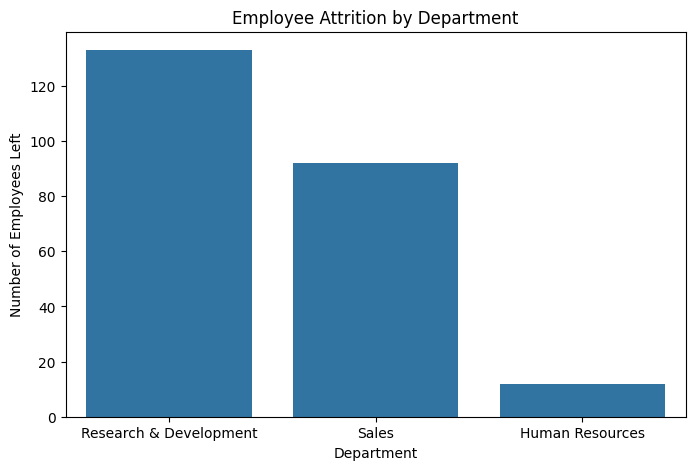

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

dept_attrition = df[df["Attrition"] == "Yes"]["Department"].value_counts()

print(dept_attrition)

plt.figure(figsize=(8, 5))
sns.barplot(x=dept_attrition.index, y=dept_attrition.values)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees Left")
plt.show()


In [ ]:

dept_summary = df.groupby("Department").agg(
    Total_Employees=("EmployeeNumber", "count"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

dept_summary["Attrition_Rate_%"] = (
    dept_summary["Employees_Left"] /
    dept_summary["Total_Employees"] * 100
).round(2)

print(dept_summary.sort_values("Attrition_Rate_%", ascending=False))


                        Total_Employees  Employees_Left  Attrition_Rate_%
Department                                                               
Sales                               446              92             20.63
Human Resources                      63              12             19.05
Research & Development              961             133             13.84


Average Monthly Income by Attrition:
Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64


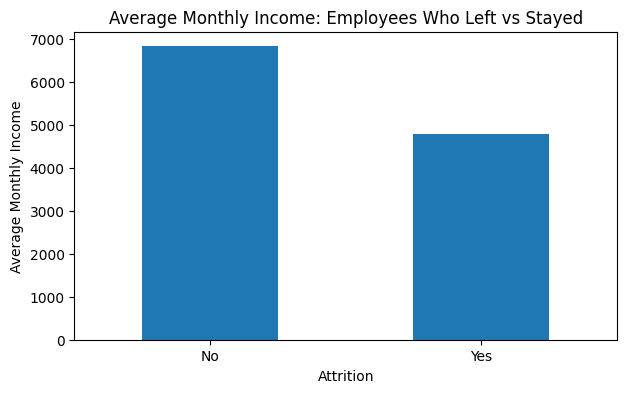

In [ ]:

income_analysis = df.groupby("Attrition")["MonthlyIncome"].mean().round(2)

print("Average Monthly Income by Attrition:")
print(income_analysis)

income_analysis.plot(kind="bar", figsize=(7, 4))
plt.title("Average Monthly Income: Employees Who Left vs Stayed")
plt.xlabel("Attrition")
plt.ylabel("Average Monthly Income")
plt.xticks(rotation=0)
plt.show()


Employees Left by Age Group:
Age_Group
18-25     44
26-35    116
36-45     43
46-55     26
56-65      8
Name: count, dtype: int64


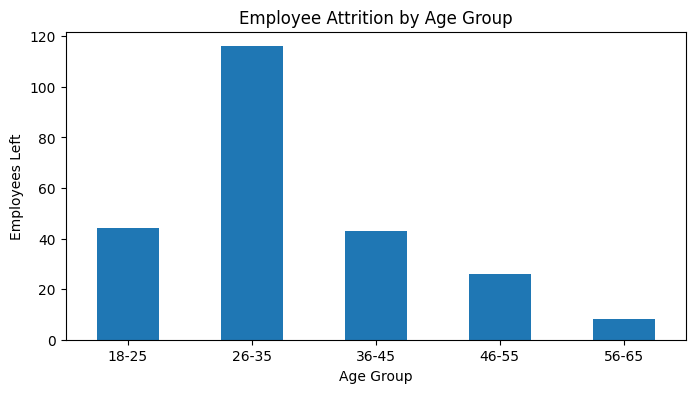

In [ ]:

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

age_attrition = df[df["Attrition"] == "Yes"]["Age_Group"].value_counts().sort_index()

print("Employees Left by Age Group:")
print(age_attrition)

age_attrition.plot(kind="bar", figsize=(8, 4))
plt.title("Employee Attrition by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Employees Left")
plt.xticks(rotation=0)
plt.show()


In [ ]:

age_summary = df.groupby("Age_Group", observed=False).agg(
    Total_Employees=("Attrition", "size"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

age_summary["Attrition_Rate_%"] = (
    age_summary["Employees_Left"] /
    age_summary["Total_Employees"] * 100
).round(2)

print(age_summary)


           Total_Employees  Employees_Left  Attrition_Rate_%
Age_Group                                                   
18-25                  123              44             35.77
26-35                  606             116             19.14
36-45                  468              43              9.19
46-55                  226              26             11.50
56-65                   47               8             17.02


In [ ]:

gender_summary = df.groupby("Gender").agg(
    Total_Employees=("Attrition", "size"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

gender_summary["Attrition_Rate_%"] = (
    gender_summary["Employees_Left"] /
    gender_summary["Total_Employees"] * 100
).round(2)

print(gender_summary)


        Total_Employees  Employees_Left  Attrition_Rate_%
Gender                                                   
Female              588              87             14.80
Male                882             150             17.01


In [ ]:

job_role_summary = df.groupby("JobRole").agg(
    Total_Employees=("Attrition", "size"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

job_role_summary["Attrition_Rate_%"] = (
    job_role_summary["Employees_Left"] /
    job_role_summary["Total_Employees"] * 100
).round(2)

job_role_summary = job_role_summary.sort_values(
    "Attrition_Rate_%", ascending=False
)

print(job_role_summary)


                           Total_Employees  Employees_Left  Attrition_Rate_%
JobRole                                                                     
Sales Representative                    83              33             39.76
Laboratory Technician                  259              62             23.94
Human Resources                         52              12             23.08
Sales Executive                        326              57             17.48
Research Scientist                     292              47             16.10
Manufacturing Director                 145              10              6.90
Healthcare Representative              131               9              6.87
Manager                                102               5              4.90
Research Director                       80               2              2.50


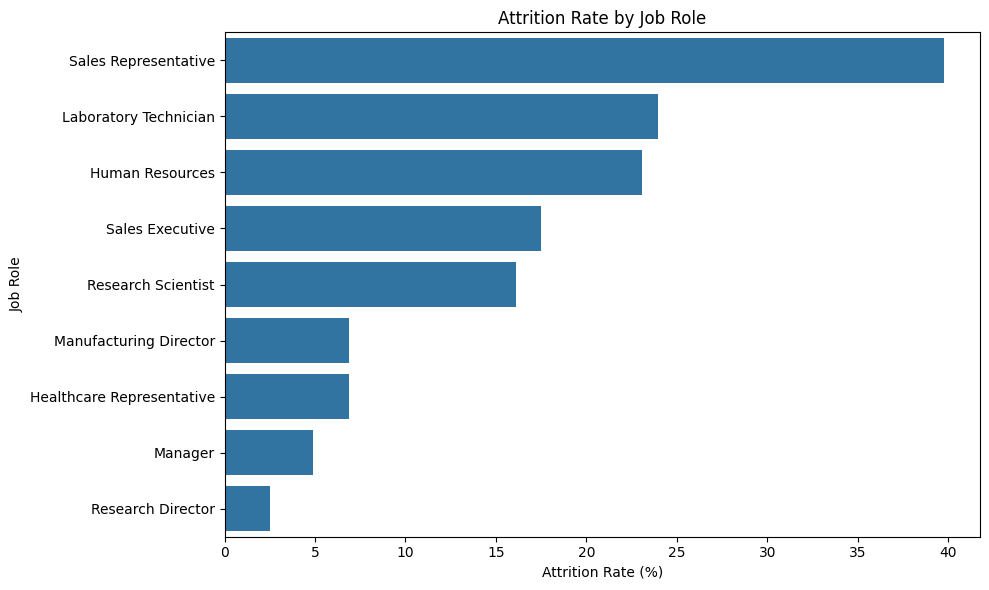

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    x=job_role_summary["Attrition_Rate_%"],
    y=job_role_summary.index
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()


In [ ]:

overtime_summary = df.groupby("OverTime").agg(
    Total_Employees=("Attrition", "size"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

overtime_summary["Attrition_Rate_%"] = (
    overtime_summary["Employees_Left"] /
    overtime_summary["Total_Employees"] * 100
).round(2)

print(overtime_summary)


          Total_Employees  Employees_Left  Attrition_Rate_%
OverTime                                                   
No                   1054             110             10.44
Yes                   416             127             30.53


In [ ]:

tenure_summary = df.groupby("YearsAtCompany").agg(
    Total_Employees=("Attrition", "size"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

tenure_summary["Attrition_Rate_%"] = (
    tenure_summary["Employees_Left"] /
    tenure_summary["Total_Employees"] * 100
).round(2)

print(tenure_summary.sort_values("Attrition_Rate_%", ascending=False).head(10))


                Total_Employees  Employees_Left  Attrition_Rate_%
YearsAtCompany                                                   
40                            1               1            100.00
23                            2               1             50.00
0                            44              16             36.36
1                           171              59             34.50
32                            3               1             33.33
31                            3               1             33.33
2                           127              27             21.26
33                            5               1             20.00
4                           110              19             17.27
24                            6               1             16.67


In [ ]:

satisfaction_summary = df.groupby("JobSatisfaction").agg(
    Total_Employees=("Attrition", "size"),
    Employees_Left=("Attrition", lambda x: (x == "Yes").sum())
)

satisfaction_summary["Attrition_Rate_%"] = (
    satisfaction_summary["Employees_Left"] /
    satisfaction_summary["Total_Employees"] * 100
).round(2)

print(satisfaction_summary)


                 Total_Employees  Employees_Left  Attrition_Rate_%
JobSatisfaction                                                   
1                            289              66             22.84
2                            280              46             16.43
3                            442              73             16.52
4                            459              52             11.33


In [ ]:

print("HR ANALYTICS - KEY FINDINGS")
print("-" * 35)

print(f"Total Employees: {len(df)}")
print(f"Employees Left: {(df['Attrition'] == 'Yes').sum()}")
print(f"Overall Attrition Rate: {attrition_rate:.2f}%")

print("\nHighest Department Attrition Rate:")
print(dept_summary["Attrition_Rate_%"].idxmax(),
      dept_summary["Attrition_Rate_%"].max(), "%")

print("\nHighest Job Role Attrition Rate:")
print(job_role_summary["Attrition_Rate_%"].idxmax(),
      job_role_summary["Attrition_Rate_%"].max(), "%")

print("\nHighest Age Group Attrition Rate:")
print(age_summary["Attrition_Rate_%"].idxmax(),
      age_summary["Attrition_Rate_%"].max(), "%")

print("\nOvertime Attrition Rate:")
print(overtime_summary["Attrition_Rate_%"])


HR ANALYTICS - KEY FINDINGS
-----------------------------------
Total Employees: 1470
Employees Left: 237
Overall Attrition Rate: 16.12%

Highest Department Attrition Rate:
Sales 20.63 %

Highest Job Role Attrition Rate:
Sales Representative 39.76 %

Highest Age Group Attrition Rate:
18-25 35.77 %

Overtime Attrition Rate:
OverTime
No     10.44
Yes    30.53
Name: Attrition_Rate_%, dtype: float64


In [ ]:

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())


Missing Values: 0
Duplicate Rows: 0
